# Data-Driven Dimensional Analysis: Algorithms for Unique and Relevant Dimensionless Groups

__Paul G. Constantine__, Department of Computer Science, University of Colorado, Boulder, CO

__Zachary del Rosario__, Department of Aeronautics and Astronautics, Stanford University, Durand Building, 496 Lomita Mall, Stanford, CA 94305

__Gianluca Iaccarino__, Department of Mechanical Engineering and Institute for Computational Mathematical Engineering, Stanford University, Building 500, Stanford, CA 94305

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the viscous pipe flow example (Sec. 6) of [[1]][R1], an arXiv preprint (arXiv:1708.04303, 2017; we found no journal version). It runs in Python 3 with numpy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds.

[R1]: #References

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import pipe_model as pm

SEED = 1708                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
REG = pm.REGIMES                  # 'laminar', 'turbulent', 'high_re'
TITLE = {'laminar': 'laminar (Table 2)', 'turbulent': 'turbulent (Table 3)', 'high_re': 'high Re (Table 4)'}
labels = [r'$\ln\rho$', r'$\ln\mu$', r'$\ln D$', r'$\ln\varepsilon$', r'$\ln V$']


def order(v):
    """Order of magnitude of a rounding-level value (4.7e-36 -> '1e-36'); such values change between platforms."""
    return f'1e{int(np.floor(np.log10(abs(v))))}' if v != 0 else '0'

### Summary

Constantine, del Rosario and Iaccarino [[1]][R1] show that any semi-empirical model is a ridge function of the logarithms of its dimensional inputs, and that the eigenvectors of the active subspace matrix of the dimensionless output with respect to the log inputs define *unique* dimensionless groups ranked by *relevance*; they demonstrate this on the pressure loss of viscous pipe flow (Colebrook equation) in three flow regimes. We reimplement the model in numpy with exact gradients, estimate the active subspaces from 1000 Monte Carlo samples per regime, and repeat the paper's 161051-point Gauss–Legendre computation: the exponent vectors agree with the paper's Tables 5–7 (Algorithm 2) to the three printed decimals, and the eigenvalues agree to the printed digits after a constant factor of 16 that the paper's equations do not contain; the paper's figures place that factor in its computed pressure loss, which is consistent with a Darcy friction factor used in the Fanning form of the pressure drop, 4 times Eq. (61) (see the comparison section). The active subspace of the dimensionless pressure loss is one-dimensional in the laminar case (the Reynolds number, $\lambda_1/\lambda_2 = 8.0\times10^{6}$) and in the high-Reynolds case (the relative roughness, $\lambda_1/\lambda_2 = 7.5\times10^{7}$), and two-dimensional in the turbulent case ($\lambda_1/\lambda_2 = 19.9$), where the most relevant group is $Re^{0.307}(\varepsilon/D)^{-0.425}$ rather than either classical group.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. The eigenvalue $\lambda_i$ is the average squared derivative of $f$ along $\mathbf w_i$, which is the paper's notion of relevance (Sec. 4.2, Eq. (33)). We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

The independent variables are the fluid density $\rho$, viscosity $\mu$, pipe diameter $D$, wall roughness $\varepsilon$ and bulk velocity $V$ (Table 1, p. 30), ordered here as in the paper's dimension matrix (Eq. (62), p. 32). The dependent variable is the pressure loss per unit length $dp/dx$ (kg m$^{-2}$ s$^{-2}$). With $Re = \rho V D/\mu$, the paper's computational model solves the Colebrook equation (Eq. (60), p. 30)

$$
\frac{1}{\sqrt\lambda} = -2.0\,\log_{10}\left(\frac{1}{3.7}\frac{\varepsilon}{D} + \frac{2.51}{Re\sqrt\lambda}\right)
$$

for the friction factor $\lambda$ with a Newton method, "valid over a wide range of flow conditions, i.e., laminar and turbulent regimes" (p. 30), and computes (Eq. (61), p. 30)

$$
\frac{dp}{dx} = \frac{\lambda\,\rho V^2}{2D}.
$$

The paper also states the Poiseuille relation $\lambda = 64/Re$ for $Re < Re_c \approx 3000$ (Eq. (59), p. 30), but its model uses the Colebrook equation in all three cases, and so do we; the comparison section shows that the Poiseuille relation would not reproduce Table 5. `pipe_model.py` solves for $s = 1/\sqrt\lambda$ by Newton's method (relative step below $10^{-15}$) and differentiates the solution implicitly, so the gradients are exact up to rounding.

**Dimensional analysis** (Sec. 6.1, p. 32). With $\mathbf x = \ln\mathbf q$, $\mathbf q = (\rho, \mu, D, \varepsilon, V)$, the vector $\mathbf w = (1, 0, -1, 0, 2)$ solves $\mathbf D\mathbf w = (1, -2, -2)$, the dimension vector of $dp/dx$, so the dimensionless dependent variable is $\pi = (dp/dx)\exp(-\mathbf w^T\mathbf x) = (dp/dx)\,D/(\rho V^2) = \lambda/2$ (Eq. (7)). The null space of $\mathbf D$ is two-dimensional; the paper takes as its basis $\mathbf W$ the last two right singular vectors of $\mathbf D$. The classical groups are $Re$, with exponents $(1, -1, 1, 0, 1)$, and $\varepsilon/D$, with $(0, 0, -1, 1, 0)$ (Tables 5–7, columns "DA").

**Quantity of interest and coordinates.** Following Algorithms 1 and 2 (pp. 26 and 28), the active subspace is that of $\pi$ as a function of $\boldsymbol\gamma = \mathbf W^T\ln\mathbf q$, and the unique and relevant groups are $\hat\pi_i = \exp(\mathbf z_i^T\ln\mathbf q)$ with $\mathbf z_i = \mathbf W\mathbf u_i$ (Eqs. (39)–(40)). Because $\pi$ depends on $\mathbf x$ only through $\boldsymbol\gamma$, $\nabla_{\mathbf x}\pi = \mathbf W\nabla_{\boldsymbol\gamma}g$, so the $5\times5$ matrix $\mathbf C_x = \int\nabla_{\mathbf x}\pi\,\nabla_{\mathbf x}\pi^T\rho\,d\mathbf q$ equals $\mathbf W\mathbf C_\gamma\mathbf W^T$: it has the paper's two eigenvalues, its leading eigenvectors are the paper's $\mathbf z_1, \mathbf z_2$ directly, and its other three eigenvalues are zero. We work with $\mathbf C_x$ and check the identity numerically below. The paper's density is uniform on the box of the physical variables $\mathbf q$ (Sec. 4.3, Eq. (34); Sec. 6.2, p. 32), not on the box of $\ln\mathbf q$; our samples follow it.

**Inputs** (Tables 2–4, pp. 31–32), printed from `pipe_model.py`:

In [2]:
print(f"{'variable':16s} {'symbol':6s} {'units':9s}" + ''.join(f'{TITLE[r]:>30s}' for r in REG))
for j in range(5):
    row = ''.join(f'{pm.BOUNDS[r][0][j]:>14.2e} to {pm.BOUNDS[r][1][j]:<12.2e}' for r in REG)
    print(f'{pm.DESCRIPTIONS[j]:16s} {pm.NAMES[j]:6s} {pm.UNITS[j]:9s}{row}')
print()
for r in REG:
    lo, up = pm.BOUNDS[r]
    corners = np.array(np.meshgrid(*zip(lo, up), indexing='ij')).reshape(5, -1).T
    Re, rr = pm.reynolds(corners), pm.relative_roughness(corners)
    print(f'{TITLE[r]:20s} ({pm.SOURCES[r]}): Re in [{Re.min():.4g}, {Re.max():.4g}], eps/D in [{rr.min():.3g}, {rr.max():.3g}] over the box')
W = pm.null_basis()
print('\nnull-space basis W (columns; numpy SVD signs):')
print(np.array2string(W.T, precision=4))
print(f'|D W| = {np.abs(pm.DIM_MATRIX @ W).max():.1e}, D w - v(dp/dx) = {pm.DIM_MATRIX @ pm.W_PI - pm.DIM_DPDX}, '
      f'D (Re exponents) = {pm.DIM_MATRIX @ pm.W_RE}, D (eps/D exponents) = {pm.DIM_MATRIX @ pm.W_RR}')

variable         symbol units                 laminar (Table 2)           turbulent (Table 3)             high Re (Table 4)
fluid density    rho    kg/m^3         1.00e-01 to 1.40e-01          1.00e-01 to 1.40e-01          1.00e-01 to 1.40e-01    
fluid viscosity  mu     kg/(m s)       1.00e-06 to 1.00e-05          1.00e-06 to 1.00e-05          1.00e-06 to 1.00e-05    
pipe diameter    D      m              5.00e-01 to 8.00e-01          5.00e-01 to 1.00e+00          5.00e-01 to 1.00e+00    
pipe roughness   eps    m              3.00e-05 to 8.00e-05          5.00e-04 to 2.00e-03          1.00e-02 to 4.00e-02    
fluid velocity   V      m/s            2.50e-02 to 3.00e-02          2.00e+00 to 4.00e+00          5.00e+02 to 7.00e+02    

laminar (Table 2)    (Table 2, p. 31): Re in [125, 3360], eps/D in [3.75e-05, 0.00016] over the box
turbulent (Table 3)  (Table 3, p. 31): Re in [1e+04, 5.6e+05], eps/D in [0.0005, 0.004] over the box
high Re (Table 4)    (Table 4, p. 32): Re in [2.5e+06,

The laminar box reaches $Re = 3360$ at one corner, above the critical $Re_c \approx 3000$ quoted on p. 29; this does not matter for the model, which uses the Colebrook equation throughout, as the paper's does. In the laminar case the Colebrook equation is applied below the Reynolds numbers for which it was fitted; we keep it because it is the paper's model.

### Load data

`generate_data.py` drew $M = 1000$ independent Monte Carlo samples per flow case, uniform on the box of $\mathbf q$ (seed 1708), and wrote the inputs, $dp/dx$ and its exact gradient with respect to $\ln\mathbf q$ (see `DATA.md`).

In [3]:
data = {r: np.loadtxt(f'{r}.csv', delimiter=',') for r in REG}   # (M, 11): q (5), dp/dx, d(dp/dx)/d ln q (5)
for r in REG:
    print(f'{r:9s}: {data[r].shape}')

laminar  : (1000, 11)
turbulent: (1000, 11)
high_re  : (1000, 11)


This is the one cell that converts: $\mathbf x = \ln\mathbf q$, $\pi = (dp/dx)\,e^{-\mathbf w^T\mathbf x}$ and $\nabla_{\mathbf x}\pi = e^{-\mathbf w^T\mathbf x}\,(\nabla_{\mathbf x}(dp/dx) - (dp/dx)\,\mathbf w)$. We then check the files against the model at five samples, the gradients of $\pi$ against central differences in $\ln\mathbf q$ (step $10^{-6}$), and dimensional homogeneity at every sample: $\mathbf D\nabla_{\mathbf x}\pi = \mathbf 0$ ($\pi$ is invariant under changes of units) and $\mathbf D\nabla_{\mathbf x}\ln(dp/dx) = (1, -2, -2)$.

In [4]:
Q = {r: data[r][:, :5] for r in REG}
dp = {r: data[r][:, 5] for r in REG}
Gdp = {r: data[r][:, 6:] for r in REG}
X, pi, Gpi = {}, {}, {}
for r in REG:
    X[r] = np.log(Q[r])                                    # log inputs, the coordinates of the analysis
    s = np.exp(-X[r] @ pm.W_PI)                            # D / (rho V^2)
    pi[r] = dp[r] * s                                      # dimensionless pressure loss = lambda / 2
    Gpi[r] = s[:, None] * (Gdp[r] - dp[r][:, None] * pm.W_PI)

h = 1e-6
for r in REG:
    rows = np.arange(5)
    rel_f = np.max(np.abs(pm.pressure_gradient(Q[r][rows]) - dp[r][rows]) / dp[r][rows])
    Gfd = np.column_stack([(pm.dimensionless_loss(np.exp(X[r][rows] + h * e)) - pm.dimensionless_loss(np.exp(X[r][rows] - h * e))) / (2 * h)
                           for e in np.eye(5)])
    rel_g = np.max(np.linalg.norm(Gfd - Gpi[r][rows], axis=1) / np.linalg.norm(Gpi[r][rows], axis=1))
    hom1 = np.max(np.abs(Gpi[r] @ pm.DIM_MATRIX.T) / np.linalg.norm(Gpi[r], axis=1)[:, None])
    hom2 = np.max(np.abs(Gdp[r] / dp[r][:, None] @ pm.DIM_MATRIX.T - pm.DIM_DPDX))
    Re = pm.reynolds(Q[r])
    inside = bool(np.all((Q[r] >= pm.BOUNDS[r][0]) & (Q[r] <= pm.BOUNDS[r][1])))
    print(f'{r:9s}: model vs file, max relative difference {"below 1e-15" if rel_f < 1e-15 else f"{rel_f:.1e}"} (rounding level); grad pi vs central differences {rel_g:.1e}; '
          f'|D grad pi|/|grad pi| of order {order(hom1)}; |D grad ln(dp/dx) - (1,-2,-2)| of order {order(hom2)}')
    if r == 'laminar':
        ratio = pm.friction_factor(Q[r], law='poiseuille') / pm.friction_factor(Q[r])
        print(f'{"":11s}Poiseuille 64/Re over Colebrook lambda on the laminar samples: {ratio.min():.2f} to {ratio.max():.2f}')
    print(f'{"":11s}Re in [{Re.min():.4g}, {Re.max():.4g}] ({np.sum(Re > pm.RE_CRIT)} samples above 3000); '
          f'pi in [{pi[r].min():.4g}, {pi[r].max():.4g}]; all samples inside the box: {inside}')

laminar  : model vs file, max relative difference below 1e-15 (rounding level); grad pi vs central differences 5.0e-10; |D grad pi|/|grad pi| of order 1e-16; |D grad ln(dp/dx) - (1,-2,-2)| of order 1e-16
           Poiseuille 64/Re over Colebrook lambda on the laminar samples: 0.55 to 3.26
           Re in [135.1, 2551] (0 samples above 3000); pi in [0.02291, 0.07263]; all samples inside the box: True
turbulent: model vs file, max relative difference below 1e-15 (rounding level); grad pi vs central differences 7.1e-10; |D grad pi|/|grad pi| of order 1e-15; |D grad ln(dp/dx) - (1,-2,-2)| of order 1e-15
           Re in [1.342e+04, 3.698e+05] (1000 samples above 3000); pi in [0.009233, 0.01677]; all samples inside the box: True
high_re  : model vs file, max relative difference below 1e-15 (rounding level); grad pi vs central differences 4.3e-10; |D grad pi|/|grad pi| of order 1e-15; |D grad ln(dp/dx) - (1,-2,-2)| of order 1e-15
           Re in [3.119e+06, 6.546e+07] (1000 samples above 

The files agree with the model at rounding level, and the gradients of $\pi$ agree with central differences to $7.0\times10^{-10}$ or better, the truncation and rounding error of the differences (`check_accuracy.py` compares all 3000 gradients with complex-step derivatives, to $1.5\times10^{-15}$). Dimensional homogeneity holds at every sample to rounding level. No laminar sample has $Re > 3000$ (the largest is 2551), and every sample lies inside its box, so no sample is outside the paper's study. The laminar case is not laminar physics, however: on the 1000 laminar samples the Poiseuille friction factor $64/Re$ is 0.55 to 3.26 times the Colebrook value, so the laminar results below describe the Colebrook equation's extrapolation to low Reynolds numbers, as in the paper's model, not Poiseuille flow.

### Estimate the subspace

The model is cheap and smooth and we have exact gradients, so we use the gradient-based estimator (`estimator="as"`) with 500 bootstrap replicates. The library maps the inputs to normalized coordinates by an affine map; to keep the paper's coordinates $\ln\mathbf q$, we declare for every flow case a box of the same half-width $L = 1.2$ in every $\ln q_i$, centred on the box of $\ln\mathbf q$ (it contains every sample, since the widest log range, that of $\mu$, has half-width $\ln(10)/2 = 1.15$). The map is then a shift and a common scale $1/L$, so the eigenvectors are those of $\mathbf C_x$ and the eigenvalues are $L^2$ times those of $\mathbf C_x$; we divide by $L^2$ and report eigenvalues in the units of $\mathbf C_x$. This box describes only the coordinates: the samples are uniform in $\mathbf q$, as in the paper. Eigenvector signs are set with `ac.orient` to those of the paper's Algorithm 2 columns of Tables 5–7.

In [5]:
L = 1.2
PAPER_Z = {   # Algorithm 2 columns z1, z2 of Tables 5-7 (pp. 36, 38), order rho, mu, D, eps, V
    'laminar':   [[0.500, -0.500, 0.500, -0.001, 0.500], [-0.189, 0.189, 0.567, -0.756, -0.189]],
    'turbulent': [[0.309, -0.309, 0.732, -0.423, 0.309], [0.436, -0.436, -0.190, 0.627, 0.436]],
    'high_re':   [[0.000, 0.000, 0.707, -0.707, 0.000], [-0.535, 0.535, -0.267, -0.267, -0.535]]}
spaces, subs, lam, boot = {}, {}, {}, {}
print(f'L = {L}, L^2 = {L**2:.2f}; largest half-width of a ln q range: {max((np.log(pm.BOUNDS[r][1]) - np.log(pm.BOUNDS[r][0])).max() / 2 for r in REG):.4f} (mu)')
for r in REG:
    lo, up = pm.BOUNDS[r]
    c = (np.log(lo) + np.log(up)) / 2
    assert np.all(np.abs(X[r] - c) <= L)                  # every sample inside the coordinate box
    spaces[r] = ac.Uniform(c - L, c + L, names=[f'ln {n}' for n in pm.NAMES])
    sub = ac.active_subspace(space=spaces[r], X=X[r], f=pi[r], grads=Gpi[r], estimator='as', nboot=500, rng=SEED)
    ref = np.array(PAPER_Z[r]).T
    subs[r] = ac.orient(sub, by='reference', reference=ref / np.linalg.norm(ref, axis=0), columns=2)
    lam[r] = subs[r].eigenvalues / L**2
    boot[r] = subs[r].bootstrap_eigenvalues / L**2
    tol = 5 * np.finfo(float).eps * lam[r][0]
    ks, crit, k_hat = ac.dimension_criterion(subs[r], rule='evg')
    print(f'{TITLE[r]:20s}: lambda_1 = {lam[r][0]:.4g}, lambda_2 = {lam[r][1]:.4g}, lambda_1/lambda_2 = {lam[r][0] / lam[r][1]:.4g}; '
          f'lambda_2/lambda_1 = {lam[r][1] / lam[r][0]:.2g} ({100 * lam[r][1] / lam[r][0]:.2g} %); '
          f'lambda_3..5 of order {order(lam[r][2])} or below (round-off level m eps lambda_1 = {tol:.0e}); gap rule: n = {k_hat}')

L = 1.2, L^2 = 1.44; largest half-width of a ln q range: 1.1513 (mu)


laminar (Table 2)   : lambda_1 = 0.001511, lambda_2 = 1.887e-10, lambda_1/lambda_2 = 8.008e+06; lambda_2/lambda_1 = 1.2e-07 (1.2e-05 %); lambda_3..5 of order 1e-35 or below (round-off level m eps lambda_1 = 2e-18); gap rule: n = 1


turbulent (Table 3) : lambda_1 = 2.232e-05, lambda_2 = 1.123e-06, lambda_1/lambda_2 = 19.87; lambda_2/lambda_1 = 0.05 (5 %); lambda_3..5 of order 1e-36 or below (round-off level m eps lambda_1 = 2e-20); gap rule: n = 1


high Re (Table 4)   : lambda_1 = 0.0003509, lambda_2 = 4.707e-12, lambda_1/lambda_2 = 7.454e+07; lambda_2/lambda_1 = 1.3e-08 (1.3e-06 %); lambda_3..5 of order 1e-35 or below (round-off level m eps lambda_1 = 4e-19); gap rule: n = 1


**Dimension.** In every case $\lambda_3, \lambda_4, \lambda_5$ are below the round-off level $m\,\varepsilon\,\lambda_1$: they are rounding error of exact zeros (dimensional analysis leaves two groups), so the ratios $\lambda_2/\lambda_3$ are not measured gaps and are not reported. The question is only whether the second group matters. In the laminar case $\lambda_2/\lambda_1 = 1.2\times10^{-7}$ and in the high-Reynolds case $1.3\times10^{-8}$: we use $n = 1$. In the turbulent case the gap rule also picks $n = 1$, but $\lambda_2$ is 5 % of $\lambda_1$ ($\lambda_1/\lambda_2 = 19.9$), so the second group is not negligible; the leave-one-out $R^2$ below (0.958 for a quadratic in one active variable against 0.9992 in two) confirms it, and we use $n = 2$, as the paper concludes for this case ("both dimensionless groups are important", p. 37). Since $\lambda_3, \lambda_4, \lambda_5$ are exact zeros, $n = 2$ is the whole dimensionless space: in the turbulent case the active subspace ranks the two groups (a rotation of the classical pair) but reduces nothing beyond dimensional analysis.

### Results

**Eigenvalues.** The figure shows the two nonzero eigenvalues with 95 % bootstrap bands (the three rounding-level eigenvalues have no meaningful place on a log axis and are not drawn).

laminar  : lambda_1 95 % interval [0.001462, 0.001565], lambda_2 [1.726e-10, 2.08e-10], lambda_1/lambda_2 [7.166e+06, 8.959e+06]
turbulent: lambda_1 95 % interval [2.19e-05, 2.273e-05], lambda_2 [1.05e-06, 1.207e-06], lambda_1/lambda_2 [18.53, 21.37]
high_re  : lambda_1 95 % interval [0.0003397, 0.0003637], lambda_2 [4.248e-12, 5.208e-12], lambda_1/lambda_2 [6.658e+07, 8.369e+07]


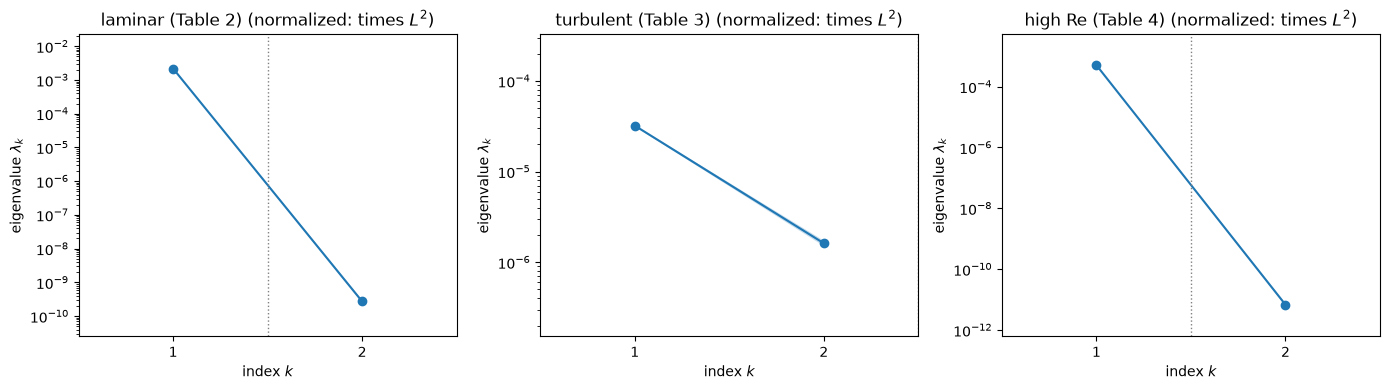

In [6]:
N_CHOSEN = {'laminar': 1, 'turbulent': 2, 'high_re': 1}
for r in REG:
    subs[r] = ac.with_dimension(subs[r], N_CHOSEN[r])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r in zip(axes, REG):
    ac.plotting.plot_eigenvalues(subs[r], ax=ax, k_max=2)
    ax.set_title(TITLE[r] + ' (normalized: times $L^2$)')
fig.tight_layout()
plt.close(fig)
for r in REG:
    b = boot[r]
    print(f'{r:9s}: lambda_1 95 % interval [{np.percentile(b[:, 0], 2.5):.4g}, {np.percentile(b[:, 0], 97.5):.4g}], '
          f'lambda_2 [{np.percentile(b[:, 1], 2.5):.4g}, {np.percentile(b[:, 1], 97.5):.4g}], '
          f'lambda_1/lambda_2 [{np.percentile(b[:, 0] / b[:, 1], 2.5):.4g}, {np.percentile(b[:, 0] / b[:, 1], 97.5):.4g}]')
fig

The plotted values are in the library's normalized coordinates, $L^2 = 1.44$ times the printed ones. Laminar: $\lambda_1 = 1.511\times10^{-3}$ (bootstrap interval $[1.462, 1.565]\times10^{-3}$) and $\lambda_2 = 1.887\times10^{-10}$, a ratio of $8.0\times10^{6}$ ($[7.2, 9.0]\times10^6$ over the replicates). Turbulent: $\lambda_1 = 2.232\times10^{-5}$ ($[2.190, 2.273]\times10^{-5}$), $\lambda_2 = 1.123\times10^{-6}$ ($[1.050, 1.207]\times10^{-6}$), ratio 19.9 ($[18.5, 21.4]$). High Re: $\lambda_1 = 3.509\times10^{-4}$ ($[3.397, 3.637]\times10^{-4}$), $\lambda_2 = 4.707\times10^{-12}$, ratio $7.5\times10^{7}$ ($[6.7, 8.4]\times10^7$).

laminar  : bootstrap mean subspace distance, k = 1: 7.8e-06; k = 2: of order 1e-14 (round-off)
turbulent: bootstrap mean subspace distance, k = 1: 0.0061; k = 2: of order 1e-16 (round-off)
high_re  : bootstrap mean subspace distance, k = 1: 2.6e-06; k = 2: of order 1e-12 (round-off)


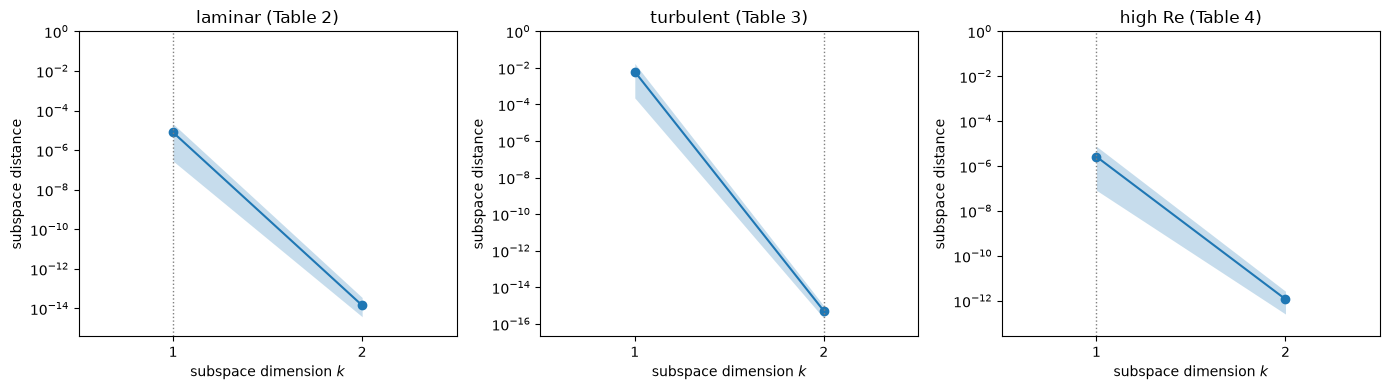

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r in zip(axes, REG):
    ac.plotting.plot_subspace_errors(subs[r], ax=ax, k_max=2)
    ax.set_title(TITLE[r])
    dist = subs[r].bootstrap_distances.mean(axis=0)
    print(f'{r:9s}: bootstrap mean subspace distance, k = 1: {dist[0]:.2g}; k = 2: of order {order(dist[1])} (round-off)')
fig.tight_layout()
plt.close(fig)
fig

The bootstrap mean distance of the one-dimensional subspace is $7.8\times10^{-6}$ (laminar), $6.1\times10^{-3}$ (turbulent) and $2.6\times10^{-6}$ (high Re), so $\mathbf z_1$ is well determined by 1000 samples in all three cases. The two-dimensional subspace has distance at rounding level in every case: it is the null space of $\mathbf D$ in every replicate, as dimensional analysis requires.

**Eigenvectors: the unique and relevant dimensionless groups.** The entries of $\mathbf z_1$ and $\mathbf z_2$ are the exponents of $\hat\pi_1$ and $\hat\pi_2$ on $(\rho, \mu, D, \varepsilon, V)$. Because both lie in the null space of $\mathbf D$, each can be written as $\mathbf z_i = a_i\,\mathbf w_{Re} + b_i\,\mathbf w_{\varepsilon/D}$, i.e. $\hat\pi_i = Re^{a_i}(\varepsilon/D)^{b_i}$, which is the paper's Eqs. (64)–(65); the cell prints $a_i, b_i$ and the residual of that fit.

laminar  : z1 = [0.4999 -0.4999 0.5004 -0.0005 0.4999], z2 = [-0.1893 0.1893 0.5666 -0.7559 -0.1893]
           pihat1 = Re^0.4999 (eps/D)^-0.0005, pihat2 = Re^-0.1893 (eps/D)^-0.7559  (fit residual of order 1e-14)
turbulent: z1 = [0.3073 -0.3073 0.7322 -0.4250 0.3073], z2 = [0.4374 -0.4374 -0.1878 0.6252 0.4374]
           pihat1 = Re^0.3073 (eps/D)^-0.4250, pihat2 = Re^0.4374 (eps/D)^0.6252  (fit residual of order 1e-16)
high_re  : z1 = [0.0001 -0.0001 0.7071 -0.7071 0.0001], z2 = [-0.5345 0.5345 -0.2672 -0.2674 -0.5345]
           pihat1 = Re^0.0001 (eps/D)^-0.7071, pihat2 = Re^-0.5345 (eps/D)^-0.2674  (fit residual of order 1e-13)


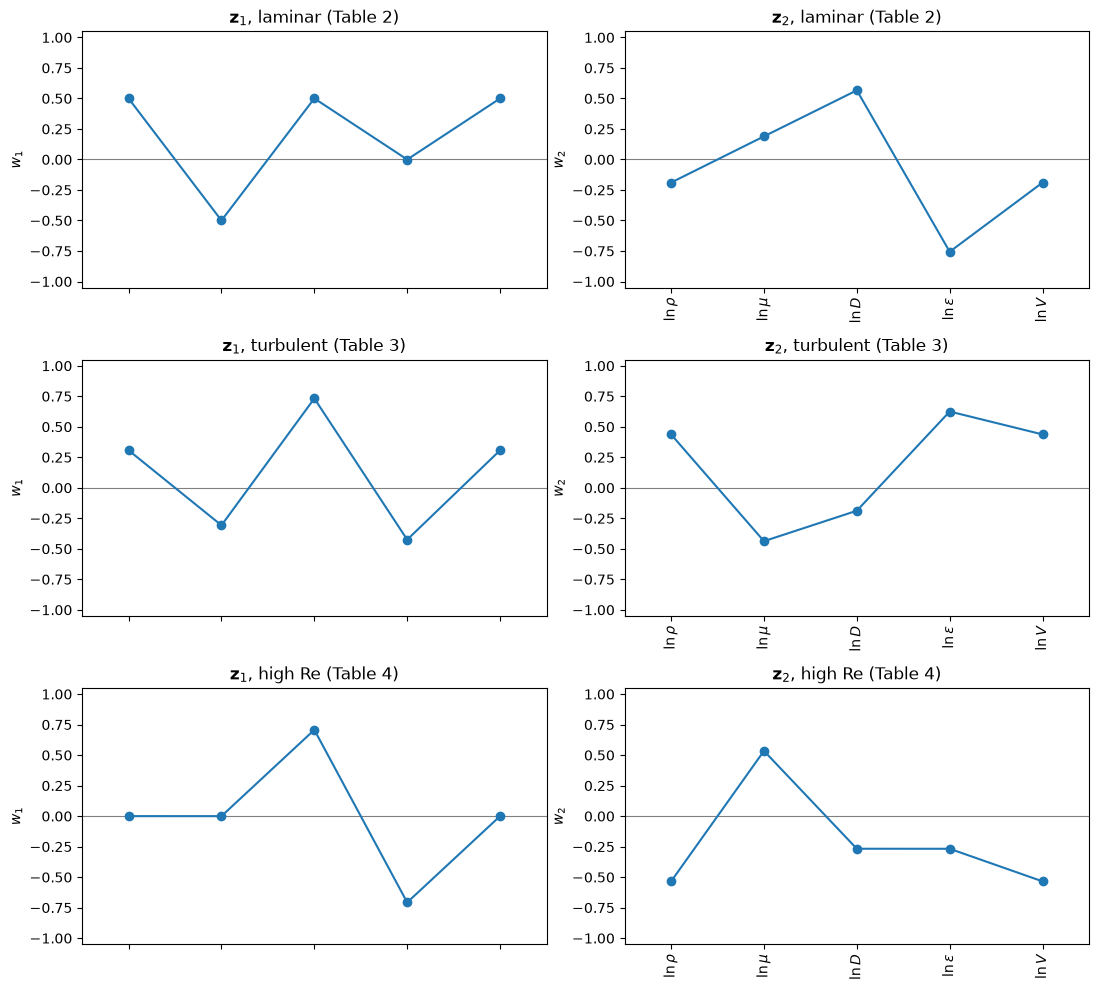

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
B = np.column_stack([pm.W_RE, pm.W_RR])
F4 = {'float_kind': lambda v: f'{v:.4f}'}
for i, r in enumerate(REG):
    ac.plotting.plot_eigenvectors(subs[r], indices=[0, 1], labels=labels, ax=list(axes[i]))
    axes[i, 0].set_title(r'$\mathbf{z}_1$, ' + TITLE[r])
    axes[i, 1].set_title(r'$\mathbf{z}_2$, ' + TITLE[r])
    Z = subs[r].W[:, :2]
    ab, *_ = np.linalg.lstsq(B, Z, rcond=None)
    res = np.abs(B @ ab - Z).max()
    print(f'{r:9s}: z1 = {np.array2string(Z[:, 0], formatter=F4)}, z2 = {np.array2string(Z[:, 1], formatter=F4)}')
    print(f'{"":11s}pihat1 = Re^{ab[0, 0]:.4f} (eps/D)^{ab[1, 0]:.4f}, pihat2 = Re^{ab[0, 1]:.4f} (eps/D)^{ab[1, 1]:.4f}  '
          f'(fit residual of order {order(res)})')
fig.tight_layout()
plt.close(fig)
fig

In the laminar case $\mathbf z_1 = (0.4999, -0.4999, 0.5004, -0.0005, 0.4999)$, i.e. $\hat\pi_1 = Re^{0.4999}(\varepsilon/D)^{-0.0005}$: up to scale, the most relevant group is the Reynolds number, and roughness hardly enters, as the Poiseuille-like behaviour of the Colebrook solution at low $Re$ implies. In the high-Reynolds case $\mathbf z_1 = (0.0001, -0.0001, 0.7071, -0.7071, 0.0001)$, i.e. $\hat\pi_1 = Re^{0.0001}(\varepsilon/D)^{-0.7071}$: the relative roughness alone, the fully rough limit. In both cases $\mathbf z_2$ is fixed by orthogonality to $\mathbf z_1$ within the null space of $\mathbf D$; with $\lambda_2/\lambda_1$ of order $10^{-7}$ and $10^{-8}$ it carries no relevance. In the turbulent case $\hat\pi_1 = Re^{0.3073}(\varepsilon/D)^{-0.4250}$ and $\hat\pi_2 = Re^{0.4374}(\varepsilon/D)^{0.6252}$: neither classical group is the most relevant one; $\hat\pi_1$ grows with the Reynolds number and falls with the roughness, which is the direction in which the friction factor changes fastest in this part of the Moody diagram.

**Sufficient summary plots.** We plot $\pi$ against the logarithm of the most relevant group, $\ln\hat\pi_1 = \mathbf z_1^T\ln\mathbf q$, a physical form of the active variable (the library's normalized active variable is $(\ln\hat\pi_1 - \mathbf z_1^T\mathbf c)/L$).

laminar  : ln pihat1 in [2.457, 3.926], ln pihat2 in [5.337, 6.603]; corr(ln pihat1, ln pi) = -0.99857
turbulent: ln pihat1 in [5.367, 7.050], ln pihat2 in [-0.253, 1.825]; corr(ln pihat1, ln pi) = -0.97801
high_re  : ln pihat1 in [1.837, 3.220], ln pihat2 in [-8.738, -7.060]; corr(ln pihat1, ln pi) = -0.99872


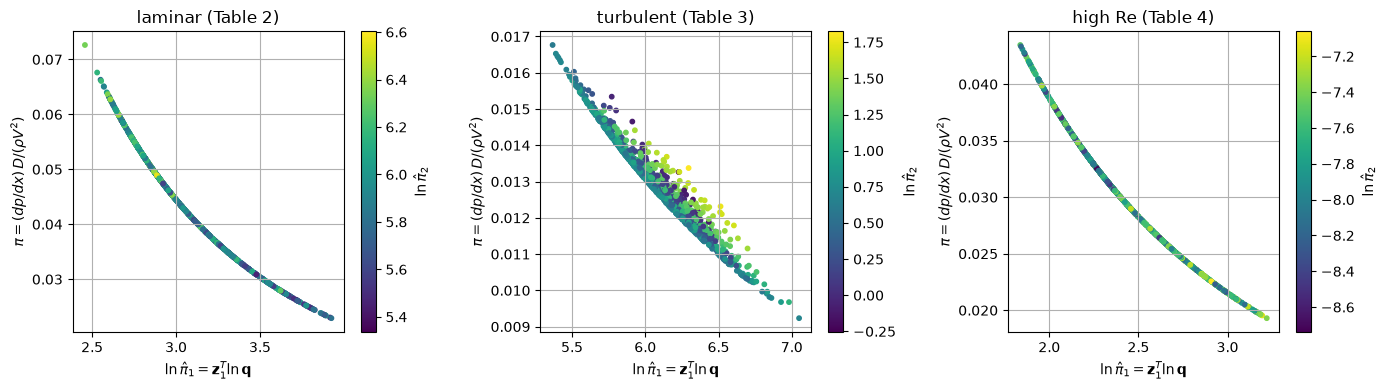

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r in zip(axes, REG):
    Z = subs[r].W[:, :2]
    y1, y2 = X[r] @ Z[:, 0], X[r] @ Z[:, 1]
    sc = ax.scatter(y1, pi[r], c=y2, s=10, cmap='viridis')
    fig.colorbar(sc, ax=ax, label=r'$\ln\hat\pi_2$')
    ax.set_xlabel(r'$\ln\hat\pi_1 = \mathbf{z}_1^T\ln\mathbf{q}$')
    ax.set_ylabel(r'$\pi = (dp/dx)\,D/(\rho V^2)$')
    ax.set_title(TITLE[r])
    ax.grid(True)
    print(f'{r:9s}: ln pihat1 in [{y1.min():.3f}, {y1.max():.3f}], ln pihat2 in [{y2.min():.3f}, {y2.max():.3f}]; '
          f'corr(ln pihat1, ln pi) = {np.corrcoef(y1, np.log(pi[r]))[0, 1]:.5f}')
fig.tight_layout()
plt.close(fig)
fig

In the laminar and high-Reynolds cases $\pi$ lies on a single smooth, convex curve in $\ln\hat\pi_1$, with no visible effect of the colour, $\ln\hat\pi_2$; the correlation of $\ln\pi$ with $\ln\hat\pi_1$ is $-0.99857$ and $-0.99872$, its departure from $-1$ coming from the curvature of the trend rather than from scatter (a cubic in $y_1$ has leave-one-out $R^2$ of 0.99998 and 0.99999 below). In the turbulent case the trend in $\ln\hat\pi_1$ is clear (correlation $-0.97801$) but the colour is layered across the band: $\hat\pi_2$ matters, as $\lambda_1/\lambda_2 = 19.9$ says. The next figure is the turbulent case in two dimensions, in the form of the paper's Fig. 6 (p. 40): $\ln\pi$ in colour against the classical groups $(\ln Re, \ln\varepsilon/D)$ and against $(\ln\hat\pi_1, \ln\hat\pi_2)$.

ln Re in [9.50, 12.82], ln(eps/D) in [-7.59, -5.59]; ln pi in [-4.685, -4.088]; ln(4 pi) in [-3.299, -2.702]


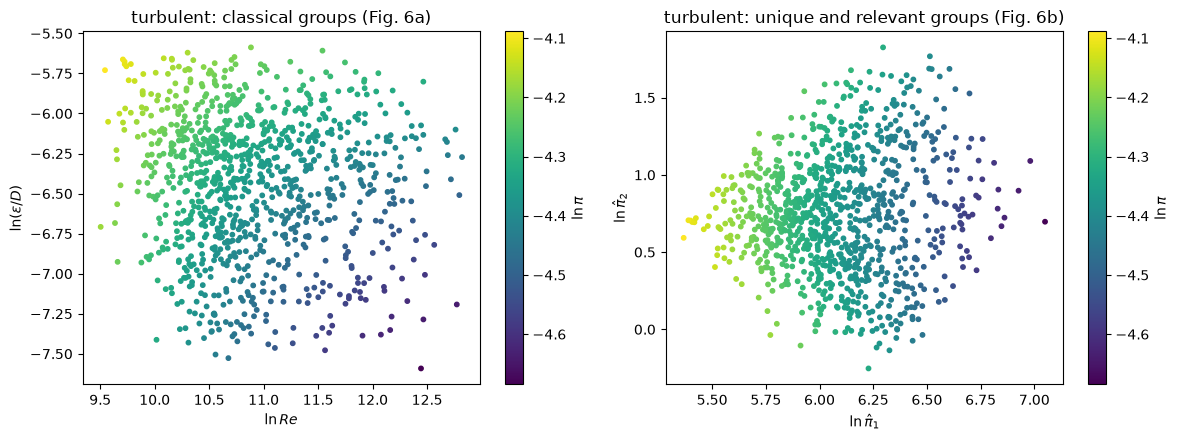

In [10]:
r = 'turbulent'
Z = subs[r].W[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pairs = [(X[r] @ pm.W_RE, X[r] @ pm.W_RR, r'$\ln Re$', r'$\ln(\varepsilon/D)$', 'classical groups (Fig. 6a)'),
         (X[r] @ Z[:, 0], X[r] @ Z[:, 1], r'$\ln\hat\pi_1$', r'$\ln\hat\pi_2$', 'unique and relevant groups (Fig. 6b)')]
for ax, (a, b, xl, yl, tt) in zip(axes, pairs):
    sc = ax.scatter(a, b, c=np.log(pi[r]), s=10, cmap='viridis')
    fig.colorbar(sc, ax=ax, label=r'$\ln\pi$')
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_title('turbulent: ' + tt)
fig.tight_layout()
plt.close(fig)
print(f'ln Re in [{(X[r] @ pm.W_RE).min():.2f}, {(X[r] @ pm.W_RE).max():.2f}], ln(eps/D) in [{(X[r] @ pm.W_RR).min():.2f}, {(X[r] @ pm.W_RR).max():.2f}]; '
      f'ln pi in [{np.log(pi[r]).min():.3f}, {np.log(pi[r]).max():.3f}]; ln(4 pi) in [{np.log(4 * pi[r]).min():.3f}, {np.log(4 * pi[r]).max():.3f}]')
fig

In the classical coordinates the colour changes along an oblique direction; in $(\ln\hat\pi_1, \ln\hat\pi_2)$ the box is rotated so that the colour changes mostly along the horizontal axis and less along the vertical one, which is the paper's reading of its Fig. 6. The ranges are compared with that figure in the comparison section.

#### Surrogates on the active variables

We fit polynomials in the active variables and report the leave-one-out $R^2$ for $\pi$: degree 2 and 3 in $y_1$, and degree 2 and 3 in $(y_1, y_2)$.

laminar   LOO R^2: n = 1, degree 2: 0.99913; n = 1, degree 3: 0.99998; n = 2, degree 2: 0.99913; n = 2, degree 3: 0.99998; 1 - R^2 (n = 1, degree 3) = 2.1e-05
turbulent LOO R^2: n = 1, degree 2: 0.95793; n = 1, degree 3: 0.95913; n = 2, degree 2: 0.99923; n = 2, degree 3: 0.99999; 1 - R^2 (n = 1, degree 3) = 0.041
high_re   LOO R^2: n = 1, degree 2: 0.99954; n = 1, degree 3: 0.99999; n = 2, degree 2: 0.99955; n = 2, degree 3: 0.99999; 1 - R^2 (n = 1, degree 3) = 7.2e-06


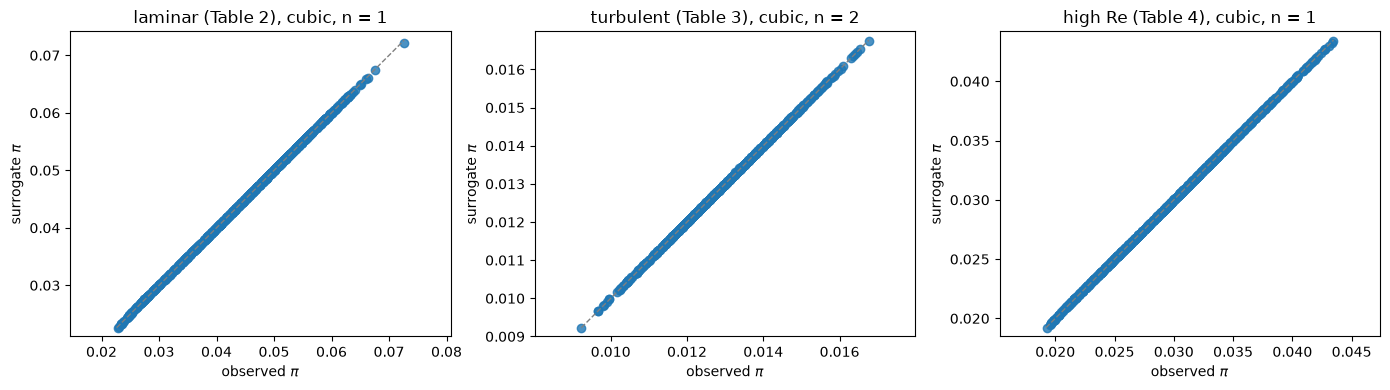

In [11]:
surs = {}
for r in REG:
    out = []
    for k, d in [(1, 2), (1, 3), (2, 2), (2, 3)]:
        s = ac.fit_surrogate(X=X[r], f=pi[r], subspace=ac.with_dimension(subs[r], k), kind='poly', degree=d)
        surs[r, k, d] = s
        out.append(f'n = {k}, degree {d}: {s.loo_r_squared:.5f}')
    print(f'{r:9s} LOO R^2: ' + '; '.join(out) + f'; 1 - R^2 (n = 1, degree 3) = {1 - surs[r, 1, 3].loo_r_squared:.2g}')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r in zip(axes, REG):
    ac.plotting.plot_surrogate_fit(surs[r, N_CHOSEN[r], 3], X=X[r], f=pi[r], qoi_label=r'$\pi$', ax=ax)
    ax.set_title(f'{TITLE[r]}, cubic, n = {N_CHOSEN[r]}')
fig.tight_layout()
plt.close(fig)
fig

In the laminar and high-Reynolds cases a cubic in one active variable has leave-one-out $R^2 = 0.99998$ and $0.99999$, and adding the second variable changes nothing in the fifth decimal. In the turbulent case one variable gives 0.95793 (quadratic) and 0.95913 (cubic), and two give 0.99923 and 0.99999: one variable leaves 4.1 % of the variance of $\pi$ unexplained (cubic), which is why we use $n = 2$ there.

**The dimensional pressure loss (Sec. 6.2).** Before nondimensionalizing, the paper checks that $dp/dx$ itself is a ridge function of $\ln\mathbf q$ with at most three active directions, the span of $\mathbf w$ and $\mathbf W$ (Lemma 1; Fig. 4, p. 34). We estimate $\mathbf C_x$ for $dp/dx$ from the same samples.

In [12]:
for r in REG:
    sd = ac.active_subspace(space=spaces[r], X=X[r], grads=Gdp[r], estimator='as', n=3)
    e = sd.eigenvalues / L**2
    P = np.column_stack([pm.W_PI, pm.null_basis()])
    Pq, _ = np.linalg.qr(P)
    out = np.linalg.norm(sd.W[:, :3] - Pq @ (Pq.T @ sd.W[:, :3]))
    print(f'{r:9s}: dp/dx eigenvalues ' + ', '.join(f'{v:.4g}' for v in e[:3]) +
          f'; lambda_4, lambda_5 of order {order(e[3])}, {order(e[4])}; distance of w1..w3 from span(w, W) of order {order(out)}')

laminar  : dp/dx eigenvalues 2.267e-10, 1.892e-13, 1.258e-18; lambda_4, lambda_5 of order 1e-42, 1e-43; distance of w1..w3 from span(w, W) of order 1e-14
turbulent: dp/dx eigenvalues 0.002919, 1.966e-06, 1.06e-07; lambda_4, lambda_5 of order 1e-35, 1e-36; distance of w1..w3 from span(w, W) of order 1e-16
high_re  : dp/dx eigenvalues 2.863e+07, 8191, 0.007735; lambda_4, lambda_5 of order 1e-25, 1e-26; distance of w1..w3 from span(w, W) of order 1e-13


For $dp/dx$ three eigenvalues are nonzero and two are at rounding level in every case, and the leading three eigenvectors span the dimensional analysis subspace $\mathrm{span}(\mathbf w, \mathbf W)$ to rounding level: $dp/dx$ is a ridge function with a three-dimensional active subspace, the conclusion of the paper's Fig. 4. With exact gradients the two zero eigenvalues are zero to rounding; in the paper's Fig. 4 they decrease with the finite difference step.

### Comparison with the paper

The paper computes its eigenpairs with a tensor Gauss–Legendre rule with 11 points per variable on the box of $\mathbf q$ (161051 points), with first-order finite differences (Algorithm 2) or with the gradient of a Gaussian process fitted to 1000 Latin hypercube samples (Algorithm 1) (Sec. 6.3, pp. 34–35). We repeat the quadrature with the same rule and exact gradients (`pipe_model.gauss_legendre`, weights summing to 1); these are the values in the table. `check_accuracy.py` shows that 15 points per variable change $\lambda_1$ by at most $1.6\times10^{-10}$ (relative).

In [13]:
PAPER_EIG = {'laminar': ((2.19e-2, 2.65e-8), (2.39e-2, 3.39e-9)),      # (Alg 1, Alg 2), Table 5 p. 36
             'turbulent': ((3.34e-4, 2.09e-5), (3.58e-4, 1.70e-5)),    # Table 6 p. 38
             'high_re': ((5.30e-3, 1.31e-10), (5.71e-3, 6.97e-11))}    # Table 7 p. 38
quad, quad_dp = {}, {}
t0 = time.perf_counter()
for r in REG:
    Qq, w = pm.gauss_legendre(r, 11)
    _, Gq = pm.dimensionless_loss(Qq, grad=True)
    _, Gq_dp = pm.pressure_gradient(Qq, grad=True)
    sq = ac.active_subspace(space=spaces[r], X=np.log(Qq), grads=Gq, quad_weights=w, estimator='as', n=N_CHOSEN[r])
    ref = np.array(PAPER_Z[r]).T
    quad[r] = ac.orient(sq, by='reference', reference=ref / np.linalg.norm(ref, axis=0), columns=2)
    quad_dp[r] = ac.active_subspace(space=spaces[r], X=np.log(Qq), grads=Gq_dp, quad_weights=w, estimator='as', n=3).eigenvalues / L**2
print(f'{len(Qq)} quadrature points per case, {time.perf_counter() - t0:.1f} s for the three cases\n')
for r in REG:
    e = quad[r].eigenvalues / L**2
    Z = quad[r].W[:, :2]
    pz = np.array(PAPER_Z[r]).T
    (a1, a2), (p1, p2) = PAPER_EIG[r]
    print(f'{TITLE[r]}: quadrature lambda_1 = {e[0]:.5g}, lambda_2 = {e[1]:.5g}; 16 x lambda = {16 * e[0]:.4g}, {16 * e[1]:.4g}; '
          f'paper Alg 2 / notebook = {p1 / e[0]:.3f}, {p2 / e[1]:.3f}; paper Alg 1 / notebook = {a1 / e[0]:.2f}, {a2 / e[1]:.3g}')
    print(f'    z1 = {np.array2string(Z[:, 0], precision=3, suppress_small=True)}, z2 = {np.array2string(Z[:, 1], precision=3, suppress_small=True)}; '
          f'max |z - paper Alg 2| = {np.abs(Z - pz).max():.4f}')
    print(f'    dp/dx (Fig. 4): 16 x (lambda_1, lambda_2, lambda_3) = ' + ', '.join(f'{16 * v:.3g}' for v in quad_dp[r][:3]) +
          ' (log10: ' + ', '.join(f'{np.log10(16 * v):.2f}' for v in quad_dp[r][:3]) + ')')
# Fig. 4 (p. 34): log10 of the three nonzero dp/dx eigenvalues read from the figure (page rendered at 400 dpi,
# markers measured against the gridlines; reading precision about 0.05 decade)
FIG4_READ = {'laminar': (-8.47, -11.53, -16.64), 'turbulent': (-1.36, -4.51, -5.73), 'high_re': (8.64, 5.15, -0.92)}
dev = max(abs(np.log10(16 * quad_dp[r][k]) - FIG4_READ[r][k]) for r in REG for k in range(3))
print(f'\nFig. 4 read from the page (log10): ' + '; '.join(f'{r} ' + ', '.join(f'{v:.2f}' for v in FIG4_READ[r]) for r in REG))
print(f'largest |log10(16 x notebook) - Fig. 4 reading| over the nine eigenvalues: {dev:.2f} decade; '
      f'without the factor 16: {min(abs(np.log10(quad_dp[r][k]) - FIG4_READ[r][k]) for r in REG for k in range(3)):.2f} decade or more')
Qt, wt = pm.gauss_legendre('turbulent', 11)
pit = pm.dimensionless_loss(Qt)
print(f'quadrature weights sum to {wt.sum():.12f}; turbulent quadrature grid: ln pi in [{np.log(pit).min():.2f}, {np.log(pit).max():.2f}], '
      f'ln(2 pi) in [{np.log(2 * pit).min():.2f}, {np.log(2 * pit).max():.2f}], ln(4 pi) in [{np.log(4 * pit).min():.2f}, {np.log(4 * pit).max():.2f}]')

161051 quadrature points per case, 0.8 s for the three cases

laminar (Table 2): quadrature lambda_1 = 0.001494, lambda_2 = 2.1162e-10; 16 x lambda = 0.0239, 3.386e-09; paper Alg 2 / notebook = 15.997, 16.019; paper Alg 1 / notebook = 14.66, 125
    z1 = [ 0.5   -0.5    0.5   -0.001  0.5  ], z2 = [-0.189  0.189  0.567 -0.756 -0.189]; max |z - paper Alg 2| = 0.0005
    dp/dx (Fig. 4): 16 x (lambda_1, lambda_2, lambda_3) = 3.53e-09, 3.16e-12, 2.28e-17 (log10: -8.45, -11.50, -16.64)
turbulent (Table 3): quadrature lambda_1 = 2.2383e-05, lambda_2 = 1.0646e-06; 16 x lambda = 0.0003581, 1.703e-05; paper Alg 2 / notebook = 15.994, 15.969; paper Alg 1 / notebook = 14.92, 19.6
    z1 = [ 0.309 -0.309  0.732 -0.423  0.309], z2 = [ 0.436 -0.436 -0.19   0.627  0.436]; max |z - paper Alg 2| = 0.0004
    dp/dx (Fig. 4): 16 x (lambda_1, lambda_2, lambda_3) = 0.0477, 3.11e-05, 1.93e-06 (log10: -1.32, -4.51, -5.71)
high Re (Table 4): quadrature lambda_1 = 0.00035666, lambda_2 = 4.3542e-12; 16 x lambda 

**The factor 16.** The exponent vectors agree with the paper's Algorithm 2 columns to the three printed decimals in all three cases (largest difference 0.0005, at the rounding of the print), but all six Algorithm 2 eigenvalues are 16 times ours to the printed digits (ratios 15.97 to 16.02). The paper's Eqs. (58), (61) and (7) give $\pi = \lambda/2$, which is what we compute. A constant factor of 16 in $\mathbf C$ is a factor of 4 in the function differentiated. Two figures of the paper locate it:

- **Fig. 4 (p. 34) puts the factor in $dp/dx$ itself.** Read from the page against its gridlines, the nine nonzero $dp/dx$ eigenvalues are $10^{-8.47}$, $10^{-11.53}$, $10^{-16.64}$ (laminar), $10^{-1.36}$, $10^{-4.51}$, $10^{-5.73}$ (turbulent) and $10^{8.64}$, $10^{5.15}$, $10^{-0.92}$ (high Re); 16 times ours are $10^{-8.45}$, $10^{-11.50}$, $10^{-16.64}$, $10^{-1.32}$, $10^{-4.51}$, $10^{-5.71}$, $10^{8.66}$, $10^{5.13}$ and $10^{-0.93}$. All nine agree within 0.04 decade (the reading precision), including the third high-Reynolds eigenvalue, whereas without the factor 16 they differ by 1.17 decades or more. So the paper's pressure loss is 4 times ours, and the factor is not in $\mathbf z$ or in the formula for $\pi$ alone.
- **Fig. 6 (p. 40) rules out the other explanations.** Its colour axis runs from about $-3.3$ to $-2.7$ in $\ln\pi$. That matches $\ln(4\pi)$ of our turbulent samples ($-3.299$ to $-2.702$; $-3.34$ to $-2.63$ on the quadrature grid), not $\ln\pi$ ($-4.685$ to $-4.088$). An error in the quadrature weights would scale the eigenvalues by 16 without shifting $\ln\pi$ (our weights sum to 1). Taking $\pi$ to be the friction factor $\lambda$ itself, a factor of 2, would put the axis at $\ln(2\pi)$, $-4.03$ to $-3.32$ on the grid. Neither fits.

The paper itself suggests a mechanism. On p. 29 it calls $\lambda$ in Eq. (58) the "Fanning friction factor", but Eq. (58), $\lambda = (dp/dx)\,D/(\tfrac12\rho V^2)$, with the Poiseuille value $64/Re$ (Eq. (59)) and the Colebrook equation (60), defines the Darcy factor; the Fanning factor is $\lambda/4$. A Darcy $\lambda$ from Colebrook used in the Fanning form of the pressure drop, $dp/dx = 2 f\rho V^2/D$, gives $2\lambda\rho V^2/D$, exactly 4 times Eq. (61). That would give $\pi = 2\lambda$ instead of $\lambda/2$ and eigenvalues 16 times ours. This is an inference from the figures and cannot be checked without the authors' code. The factor scales every eigenvalue by the same constant and leaves the exponent vectors, the eigenvalue ratios and the ranking of the groups unchanged. Our data follow Eq. (61) as printed (`pipe_model.py` uses the Darcy factor).

The cell below finishes the comparison: the Poiseuille relation in the laminar case, the rotation angle of Fig. 6, and the axis ranges of Fig. 6b.

In [14]:
Qq, w = pm.gauss_legendre('laminar', 11)
_, Gp = pm.dimensionless_loss(Qq, law='poiseuille', grad=True)
sp = ac.active_subspace(space=spaces['laminar'], X=np.log(Qq), grads=Gp, quad_weights=w, estimator='as', n=1)
ep = sp.eigenvalues / L**2
print(f'laminar, Poiseuille lambda = 64/Re instead of Colebrook: z1 = {np.array2string(np.abs(sp.W[:, 0]), precision=4)} (up to sign), '
      f'16 x lambda_1 = {16 * ep[0]:.4g} ({16 * ep[0] / 2.39e-2:.1f} times Table 5, Alg 2), lambda_2 of order {order(ep[1])} (rounding level)')
W = pm.null_basis()
U = W.T @ quad['turbulent'].W[:, :2]
print(f'turbulent: U = W^T [z1 z2] = {np.array2string(U, precision=3)}; arccos(U_11) = {np.degrees(np.arccos(U[0, 0])):.1f} degrees')
Zt = quad['turbulent'].W[:, :2]
y1, y2 = X['turbulent'] @ Zt[:, 0], X['turbulent'] @ Zt[:, 1]
print(f'turbulent samples: ln pihat1 in [{y1.min():.2f}, {y1.max():.2f}] (so -ln pihat1 in [{-y1.max():.2f}, {-y1.min():.2f}]), '
      f'ln pihat2 in [{y2.min():.2f}, {y2.max():.2f}]')

laminar, Poiseuille lambda = 64/Re instead of Colebrook: z1 = [0.5 0.5 0.5 0.  0.5] (up to sign), 16 x lambda_1 = 0.5773 (24.2 times Table 5, Alg 2), lambda_2 of order 1e-33 (rounding level)


turbulent: U = W^T [z1 z2] = [[-0.596  0.803]
 [ 0.803  0.596]]; arccos(U_11) = 126.6 degrees
turbulent samples: ln pihat1 in [5.37, 7.05] (so -ln pihat1 in [-7.05, -5.37]), ln pihat2 in [-0.28, 1.80]


With the Poiseuille relation the laminar $\mathbf z_1$ has a zero roughness exponent (roughness does not enter $64/Re$), $\lambda_2$ is at rounding level, and $16\lambda_1 = 0.5773$ is 24.2 times Table 5's 2.39e-2, while Table 5 prints $-0.001$ for $\varepsilon$ in $\mathbf z_1$ and $\lambda_2 = 3.39\times10^{-9}$ (Algorithm 2), which our Colebrook model reproduces ($16\lambda_2 = 3.386\times10^{-9}$); so the paper's laminar results come from the Colebrook equation, as p. 30 says. With numpy's SVD basis $\mathbf W$, $\arccos(U_{11}) = 126.6°$, the paper's "approximately 127 degrees" (p. 39); this angle depends on the signs of the columns of $\mathbf W$, which the paper takes from Matlab's SVD and does not print. The horizontal axis of Fig. 6b runs from $-8$ to $-5$, while $\ln\hat\pi_1 = \mathbf z_1^T\ln\mathbf q$ with Table 6's sign of $\mathbf z_1$ lies in $[5.37, 7.05]$ on our samples; $-\ln\hat\pi_1$ lies in $[-7.05, -5.37]$, so the figure appears to use $-\mathbf z_1$ (an eigenvector's sign is arbitrary). Its vertical axis, $-0.5$ to $2$, contains our $\ln\hat\pi_2 \in [-0.28, 1.80]$.

| Quantity | Paper value | Notebook value |
|---|---|---|
| Laminar $\mathbf z_1$ ($\rho, \mu, D, \varepsilon, V$) | Alg 2: 0.500, −0.500, 0.500, −0.001, 0.500 (Table 5, p. 36) | quadrature: 0.500, −0.500, 0.500, −0.001, 0.500; Monte Carlo: 0.4999, −0.4999, 0.5004, −0.0005, 0.4999 |
| Laminar $\mathbf z_2$ | Alg 2: −0.189, 0.189, 0.567, −0.756, −0.189 (Table 5) | quadrature: −0.189, 0.189, 0.567, −0.756, −0.189 |
| Laminar $\lambda_1$, $\lambda_2$ | Alg 2: 2.39e-2, 3.39e-9; Alg 1: 2.19e-2, 2.65e-8 (Table 5) | quadrature: 1.4940e-3, 2.1162e-10 (×16: 2.390e-2, 3.386e-9); Monte Carlo: 1.511e-3 [1.462e-3, 1.565e-3], 1.887e-10 |
| Turbulent $\mathbf z_1$ | Alg 2: 0.309, −0.309, 0.732, −0.423, 0.309 (Table 6, p. 38) | quadrature: 0.309, −0.309, 0.732, −0.423, 0.309; Monte Carlo: 0.3073, −0.3073, 0.7322, −0.4250, 0.3073 |
| Turbulent $\mathbf z_2$ | Alg 2: 0.436, −0.436, −0.190, 0.627, 0.436 (Table 6) | quadrature: 0.436, −0.436, −0.190, 0.627, 0.436 |
| Turbulent $\lambda_1$, $\lambda_2$ | Alg 2: 3.58e-4, 1.70e-5; Alg 1: 3.34e-4, 2.09e-5 (Table 6) | quadrature: 2.2383e-5, 1.0646e-6 (×16: 3.581e-4, 1.703e-5); Monte Carlo: 2.232e-5 [2.190e-5, 2.273e-5], 1.123e-6 [1.050e-6, 1.207e-6] |
| Turbulent groups | Alg 2: $\hat\pi_1 = Re^{0.309}(\varepsilon/D)^{-0.423}$, $\hat\pi_2 = Re^{0.436}(\varepsilon/D)^{0.627}$ (Eq. (65), p. 37) | Monte Carlo: $Re^{0.3073}(\varepsilon/D)^{-0.4250}$, $Re^{0.4374}(\varepsilon/D)^{0.6252}$ |
| High Re $\mathbf z_1$ | Alg 2: 0.000, 0.000, 0.707, −0.707, 0.000 (Table 7, p. 38) | quadrature: 0.000, 0.000, 0.707, −0.707, 0.000; Monte Carlo: 0.0001, −0.0001, 0.7071, −0.7071, 0.0001 |
| High Re $\mathbf z_2$ | Alg 2: −0.535, 0.535, −0.267, −0.267, −0.535 (Table 7) | quadrature: −0.535, 0.535, −0.267, −0.267, −0.535 |
| High Re $\lambda_1$, $\lambda_2$ | Alg 2: 5.71e-3, 6.97e-11; Alg 1: 5.30e-3, 1.31e-10 (Table 7) | quadrature: 3.5666e-4, 4.3542e-12 (×16: 5.706e-3, 6.967e-11); Monte Carlo: 3.509e-4 [3.397e-4, 3.637e-4], 4.707e-12 |
| Rank of $\mathbf C$ for $dp/dx$ | 3: two eigenvalues go to zero with the step (Fig. 4, p. 34) | 3: $\lambda_4, \lambda_5$ at rounding level (exact gradients) |
| Eigenvalues of $\mathbf C$ for $dp/dx$ (log10) | read from Fig. 4 against its gridlines: −8.47, −11.53, −16.64; −1.36, −4.51, −5.73; 8.64, 5.15, −0.92 (p. 34) | quadrature ×16: −8.45, −11.50, −16.64; −1.32, −4.51, −5.71; 8.66, 5.13, −0.93 (all nine within 0.04 decade) |
| Rotation of Fig. 6b from Fig. 6a | approximately 127° (p. 39) | 126.6° (numpy SVD signs of $\mathbf W$) |
| Colour range of Fig. 6 ($\ln\pi$) | about −3.3 to −2.7 (p. 40) | $\ln\pi$: −4.685 to −4.088; $\ln(4\pi)$: −3.299 to −2.702 |
| Leave-one-out $R^2$ | not reported | see the surrogate section |

The Algorithm 1 values differ from Algorithm 2 in the paper itself (for example laminar $\lambda_1$ 2.19e-2 against 2.39e-2, and $\lambda_2$ 2.65e-8 against 3.39e-9), which the paper attributes to the error of the Gaussian process surface (p. 40); our exact-gradient values match Algorithm 2, which has no surface error.

### References

[1] P. G. Constantine, Z. del Rosario, and G. Iaccarino. [Data-driven dimensional analysis: algorithms for unique and relevant dimensionless groups](https://doi.org/10.48550/arXiv.1708.04303). arXiv:1708.04303, 2017 (preprint; we found no journal version). The paper's code was posted at <https://bitbucket.org/paulcon/pipe-code> (p. 29; not used for this data set).

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] C. F. Colebrook and C. M. White. [Experiments with fluid friction in roughened pipes](https://doi.org/10.1098/rspa.1937.0150). *Proceedings of the Royal Society of London. Series A*, 161(906):367–381, 1937. (The paper's reference [61] for Eq. (60).)

### Acknowledgments

The paper's work was supported by the Defense Advanced Research Projects Agency's program Enabling Quantification of Uncertainty in Physical Systems; by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program, under Award Number DE-SC-0011077 (first author); and by a National Science Foundation Graduate Research Fellowship under Grant No. DGE-114747 (second author).

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 6.7 s
